# 4.10 · 03 — DL-експерименти, фінальна оцінка, error analysis
**Протокол**
1. Контрольовані runs **D1 → D2 → D3**, у кожному змінюється **один** фактор (config.json):
   - D1 — базова CNN (2 згорткові блоки), без регуляризації;
   - D2 — D1 **+ Dropout 0.3 і L2 1e-4** (регуляризація);
   - D3 — D2 **+ аугментація** (випадковий зсув ±1 px, поворот ±~15°) — зміна даних.
2. Кожен run повторюється з 3 seeds (42, 43, 44) → середнє ± std, щоб відрізнити ефект від шуму ініціалізації.
3. **Правило вибору (зафіксоване до запуску):** середнє з val macro-F1 на чистих даних і на validation із domain shift (шум σ=0.15 та зсув 1 px). За рівності — простіша модель.
4. Test використовується **один раз** для FINAL і baseline (B0).

**Чому така архітектура:** вхід 8×8 дуже малий, тому лише два pooling (8→4→2), фільтри 3×3 з `padding="same"`, мала кількість параметрів (~60 тис.) — під 1078 тренувальних зображень. Loss — sparse categorical cross-entropy (10 взаємовиключних класів), optimizer — Adam (lr 1e-3), early stopping за `val_loss` з відновленням найкращих ваг.

In [1]:
import sys, json, time, os
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, classification_report
from src.utils import (load_config, set_seed, load_split, build_cnn, add_noise, shift_images, RESULTS)

cfg = load_config()
data = load_split()
(Xtr, ytr), (Xva, yva), (Xte, yte) = data["train"], data["val"], data["test"]
ds = cfg["domain_shift"]; tr = cfg["training"]; au = cfg["augmentation"]
SEEDS = [cfg["seed"], cfg["seed"] + 1, cfg["seed"] + 2]

# Validation-версії з domain shift (для вибору моделі), test-версії — для фінальної оцінки
shifted = lambda X, seed: {"clean": X, "noise": add_noise(X, ds["noise_sigma"], seed),
                           "shift": shift_images(X, ds["shift_pixels"], seed)}
VAL = shifted(Xva, 1)
TEST = shifted(Xte, 2)
mf1 = lambda y, p: f1_score(y, p, average="macro")
print("TF", tf.__version__, "| train/val/test:", len(ytr), len(yva), len(yte))

TF 2.21.0 | train/val/test: 1077 360 360


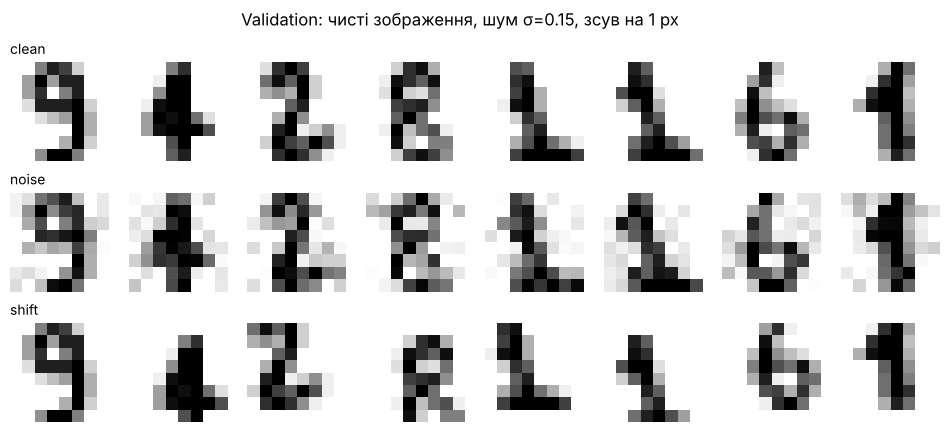

In [2]:
fig, axes = plt.subplots(3, 8, figsize=(12, 4.8))
for r, key in enumerate(["clean", "noise", "shift"]):
    for c in range(8):
        axes[r, c].imshow(VAL[key][c], cmap="gray_r", vmin=0, vmax=1); axes[r, c].axis("off")
    axes[r, 0].set_title(key, loc="left", fontsize=10)
plt.suptitle("Validation: чисті зображення, шум σ=0.15, зсув на 1 px"); plt.show()

## 1. Baseline B0 на тому самому протоколі

In [3]:
flat = lambda X: X.reshape(len(X), -1)
base_cfg = json.load(open(RESULTS / "baseline.json"))
t0 = time.time()
b0 = LogisticRegression(C=base_cfg["C"], max_iter=cfg["baseline"]["max_iter"]).fit(flat(Xtr), ytr)
b0_time = time.time() - t0
b0_row = {"Run": "B0", "Hypothesis": "baseline", "Change": f"LogReg на пікселях, C={base_cfg['C']}",
          "Train metric": mf1(ytr, b0.predict(flat(Xtr))),
          "Validation metric": mf1(yva, b0.predict(flat(VAL["clean"]))),
          "Val noise": mf1(yva, b0.predict(flat(VAL["noise"]))),
          "Val shift": mf1(yva, b0.predict(flat(VAL["shift"]))),
          "Std (seeds)": 0.0, "Params": 64 * 10 + 10, "Time, s": b0_time}
b0_row

{'Run': 'B0',
 'Hypothesis': 'baseline',
 'Change': 'LogReg на пікселях, C=10.0',
 'Train metric': 0.9990564148214087,
 'Validation metric': 0.9750906990834102,
 'Val noise': 0.9473122252682915,
 'Val shift': 0.35079037326909557,
 'Std (seeds)': 0.0,
 'Params': 650,
 'Time, s': 0.040805816650390625}

## 2. Контрольовані експерименти D1–D3

In [4]:
HYP = {"D1": ("DL should capture nonlinear/spatial structure", "base CNN"),
       "D2": ("regularization may reduce overfit", "+ dropout 0.3 / L2 1e-4"),
       "D3": ("augmentation may improve generalization under shift", "+ augmentation (shift/rotate)")}

def train_run(rc, seed):
    set_seed(seed)
    model = build_cnn(rc["filters"], rc["dense"], rc["dropout"], rc["l2"], rc["augment"],
                      au["translation"], au["rotation"], tr["learning_rate"])
    es = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=tr["early_stopping_patience"],
                                          restore_best_weights=True)
    t0 = time.time()
    h = model.fit(Xtr[..., None], ytr, validation_data=(Xva[..., None], yva), epochs=tr["epochs"],
                  batch_size=tr["batch_size"], callbacks=[es], verbose=0)
    return model, h.history, time.time() - t0

pred = lambda m, X: m.predict(X[..., None], verbose=0).argmax(1)

rows, histories, models = [b0_row], {}, {}
for run, rc in cfg["runs"].items():
    per_seed = []
    for seed in SEEDS:
        m, h, t = train_run(rc, seed)
        per_seed.append({"train": mf1(ytr, pred(m, Xtr)), "val": mf1(yva, pred(m, VAL["clean"])),
                         "noise": mf1(yva, pred(m, VAL["noise"])), "shift": mf1(yva, pred(m, VAL["shift"])),
                         "time": t, "epochs": len(h["loss"])})
        if seed == SEEDS[0]:
            models[run], histories[run] = m, h
    ps = pd.DataFrame(per_seed)
    rows.append({"Run": run, "Hypothesis": HYP[run][0], "Change": HYP[run][1],
                 "Train metric": ps["train"].mean(), "Validation metric": ps["val"].mean(),
                 "Val noise": ps["noise"].mean(), "Val shift": ps["shift"].mean(),
                 "Std (seeds)": ps["val"].std(), "Params": models[run].count_params(),
                 "Time, s": ps["time"].mean()})
    print(f"{run}: val F1 = {ps['val'].mean():.4f} ± {ps['val'].std():.4f}, епох ≈ {ps['epochs'].mean():.0f}")

exp = pd.DataFrame(rows)
exp["Generalization gap"] = exp["Train metric"] - exp["Validation metric"]
exp["Selection score"] = (exp["Validation metric"] + (exp["Val noise"] + exp["Val shift"]) / 2) / 2
exp.round(4)

D1: val F1 = 0.9835 ± 0.0056, епох ≈ 38


D2: val F1 = 0.9880 ± 0.0070, епох ≈ 44


D3: val F1 = 0.9812 ± 0.0184, епох ≈ 65


,Run,Hypothesis,Change,Train metric,Validation metric,Val noise,Val shift,Std (seeds),Params,"Time, s",Generalization gap,Selection score
0,B0,baseline,"LogReg на пікселях, C=10.0",0.9991,0.9751,0.9473,0.3508,0.0000,650,0.0408,0.0240,0.8121
1,D1,DL should capture nonlinear/spatial structure,base CNN,0.9972,0.9835,0.9610,0.5281,0.0056,45162,10.6583,0.0137,0.8640
2,D2,regularization may reduce overfit,+ dropout 0.3 / L2 1e-4,0.9994,0.9880,0.9713,0.5768,0.0070,45162,12.8571,0.0113,0.8811
3,D3,augmentation may improve generalization under ...,+ augmentation (shift/rotate),0.9944,0.9812,0.9544,0.9573,0.0184,45162,19.9723,0.0132,0.9685


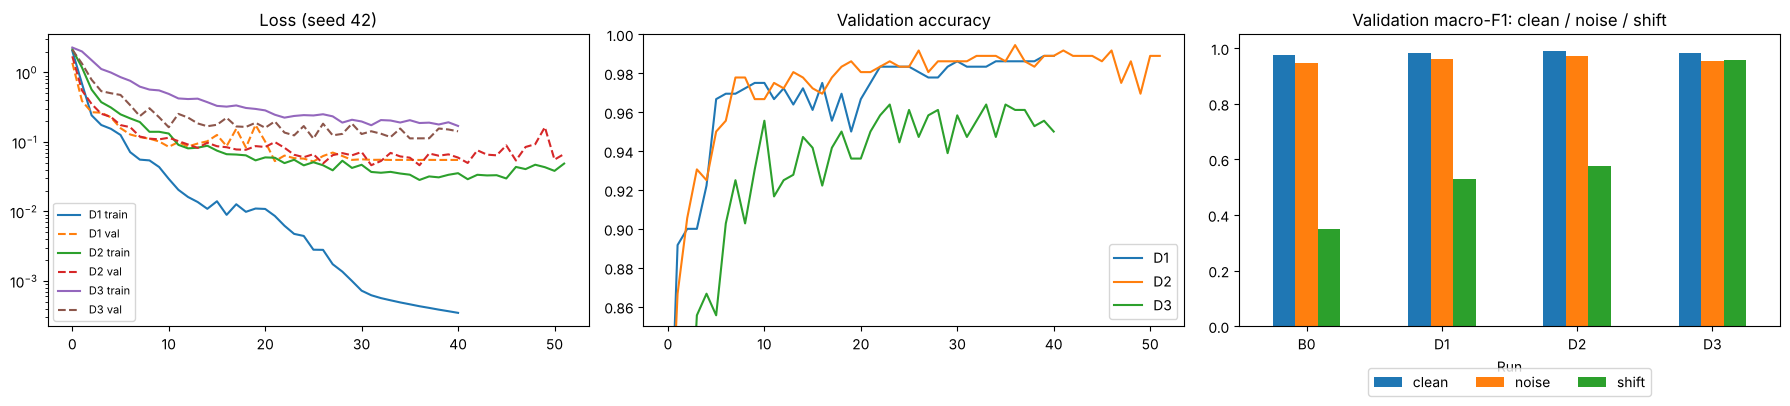

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
for run, h in histories.items():
    axes[0].plot(h["loss"], label=f"{run} train"); axes[0].plot(h["val_loss"], "--", label=f"{run} val")
    axes[1].plot(h["val_accuracy"], label=run)
axes[0].set_yscale("log"); axes[0].set_title("Loss (seed 42)"); axes[0].legend(fontsize=8)
axes[1].set_title("Validation accuracy"); axes[1].legend(); axes[1].set_ylim(0.85, 1.0)
exp.set_index("Run")[["Validation metric", "Val noise", "Val shift"]].plot.bar(ax=axes[2], rot=0)
axes[2].set_ylim(0.0, 1.05); axes[2].set_title("Validation macro-F1: clean / noise / shift")
axes[2].legend(["clean", "noise", "shift"], loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)
plt.tight_layout(); plt.show()

## 3. Вибір FINAL (лише за validation) і заморожування

In [6]:
dl = exp[exp["Run"].str.startswith("D")]
best_score = dl["Selection score"].max()
# за рівності (в межах 0.002) — простіша модель (менший номер run)
final_run = dl[dl["Selection score"] >= best_score - 0.002].iloc[0]["Run"]
final_model = models[final_run]
print("FINAL =", final_run, "|", cfg["runs"][final_run])
final_model.save(RESULTS / "final_model.keras")
print("Модель збережено: results/final_model.keras")

FINAL = D3 | {'filters': [32, 64], 'dense': 64, 'dropout': 0.3, 'l2': 0.0001, 'augment': True}
Модель збережено: results/final_model.keras


## 4. Final evaluation на test (один раз)

In [7]:
final_rows = []
for name, predict in [("B0 LogReg", lambda X: b0.predict(flat(X))), (f"FINAL ({final_run})", lambda X: pred(final_model, X))]:
    r = {"Model": name}
    for key in ["clean", "noise", "shift"]:
        p = predict(TEST[key])
        r[f"test macro-F1 {key}"] = mf1(yte, p)
        r[f"test acc {key}"] = accuracy_score(yte, p)
    final_rows.append(r)
final = pd.DataFrame(final_rows).set_index("Model")
final.round(4)

,test macro-F1 clean,test acc clean,test macro-F1 noise,test acc noise,test macro-F1 shift,test acc shift
Model,,,,,,
B0 LogReg,0.9579,0.9583,0.9384,0.9389,0.3409,0.3472
FINAL (D3),0.9521,0.9528,0.9381,0.9389,0.9075,0.9083


In [8]:
y_final = pred(final_model, TEST["clean"])
print(classification_report(yte, y_final, digits=3))

              precision    recall  f1-score   support

           0      1.000     0.972     0.986        36
           1      0.917     0.917     0.917        36
           2      0.875     1.000     0.933        35
           3      0.973     0.973     0.973        37
           4      0.921     0.972     0.946        36
           5      0.949     1.000     0.974        37
           6      0.973     1.000     0.986        36
           7      0.972     0.972     0.972        36
           8      1.000     0.829     0.906        35
           9      0.970     0.889     0.928        36

    accuracy                          0.953       360
   macro avg      0.955     0.952     0.952       360
weighted avg      0.955     0.953     0.952       360



## 5. Error analysis

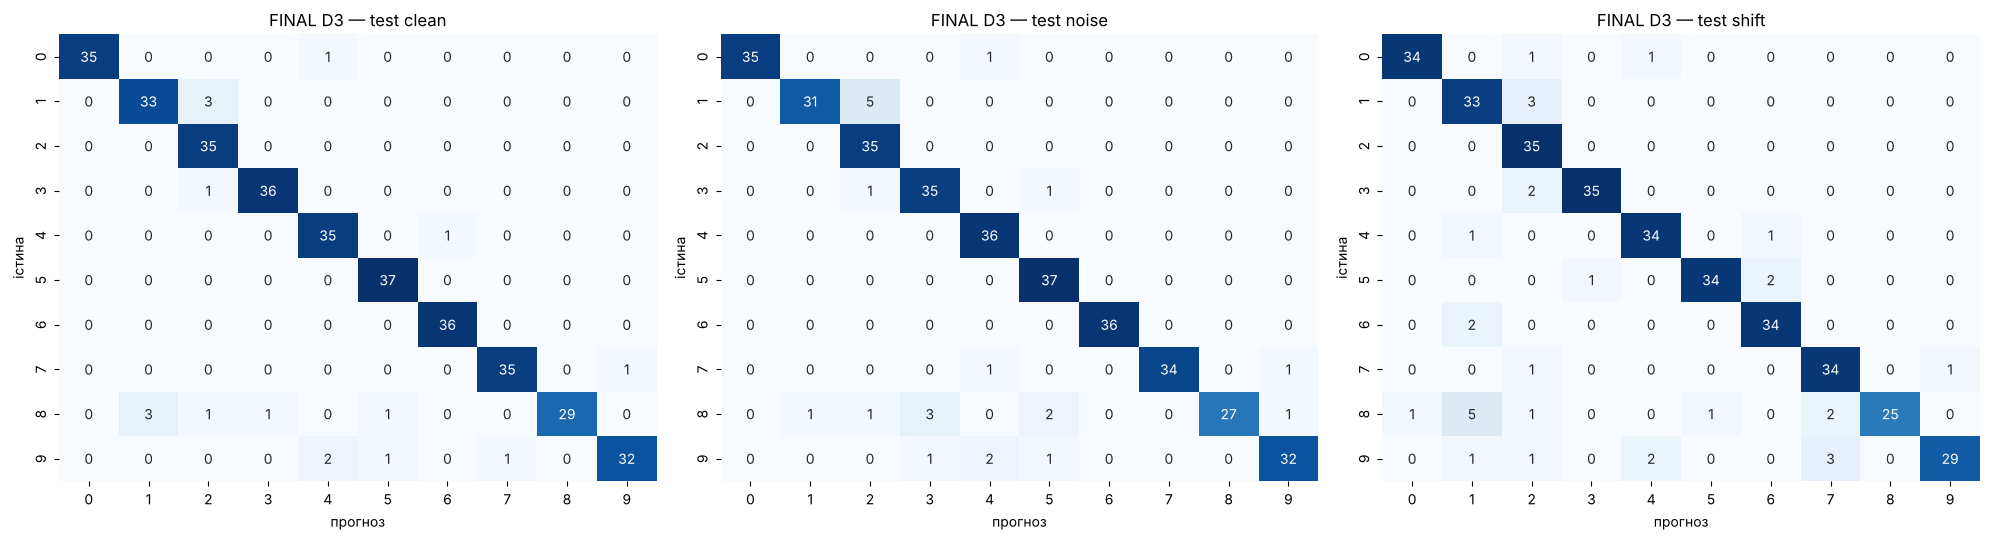

clean | FINAL: 8→1 (3), 1→2 (3), 9→4 (2), 9→7 (1), 9→5 (1)
      | B0:    8→1 (4), 1→8 (3), 9→4 (2), 9→8 (1), 8→5 (1)
noise | FINAL: 1→2 (5), 8→3 (3), 9→4 (2), 8→5 (2), 9→5 (1)
      | B0:    9→4 (3), 8→1 (3), 1→8 (3), 9→8 (1), 8→5 (1)
shift | FINAL: 8→1 (5), 9→7 (3), 1→2 (3), 9→4 (2), 8→7 (2)
      | B0:    8→4 (20), 5→4 (19), 6→4 (14), 9→4 (11), 7→4 (11)


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for ax, key in zip(axes, ["clean", "noise", "shift"]):
    cm = confusion_matrix(yte, pred(final_model, TEST[key]))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(f"FINAL {final_run} — test {key}"); ax.set_xlabel("прогноз"); ax.set_ylabel("істина")
plt.tight_layout(); plt.show()

def top_confusions(y_true, y_pred, k=5):
    cm = confusion_matrix(y_true, y_pred); np.fill_diagonal(cm, 0)
    pairs = sorted(((cm[i, j], i, j) for i in range(10) for j in range(10) if cm[i, j]), reverse=True)[:k]
    return [f"{i}→{j} ({n})" for n, i, j in pairs]

conf = {key: top_confusions(yte, pred(final_model, TEST[key])) for key in TEST}
conf_b0 = {key: top_confusions(yte, b0.predict(flat(TEST[key]))) for key in TEST}
for key in TEST:
    print(f"{key:5s} | FINAL: {', '.join(conf[key]) or '—'}\n      | B0:    {', '.join(conf_b0[key]) or '—'}")

Помилок на чистому тесті: 17 з 360
Середня впевненість: правильні 0.983, помилкові 0.651


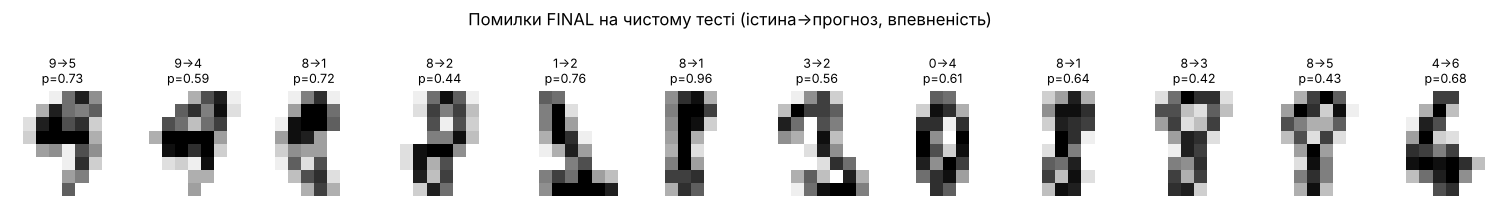

Зсув 1 px: помилок B0 = 235, FINAL = 33, обидві помиляються = 31


In [10]:
proba = final_model.predict(TEST["clean"][..., None], verbose=0)
wrong = np.where(y_final != yte)[0]
conf_wrong = proba[wrong].max(1)
conf_right = proba[y_final == yte].max(1)
print(f"Помилок на чистому тесті: {len(wrong)} з {len(yte)}")
print(f"Середня впевненість: правильні {conf_right.mean():.3f}, помилкові {conf_wrong.mean():.3f}" if len(wrong) else "")

if len(wrong):
    n = min(len(wrong), 12)
    fig, axes = plt.subplots(1, n, figsize=(1.6 * n, 2.3), squeeze=False)
    for ax, i in zip(axes[0], wrong[:n]):
        ax.imshow(TEST["clean"][i], cmap="gray_r"); ax.axis("off")
        ax.set_title(f"{yte[i]}→{y_final[i]}\np={proba[i].max():.2f}", fontsize=9)
    plt.suptitle("Помилки FINAL на чистому тесті (істина→прогноз, впевненість)", y=1.08); plt.show()

# Помилки на зсунутих даних: що «ламається» в baseline, але ні в CNN
b0_shift_wrong = b0.predict(flat(TEST["shift"])) != yte
cnn_shift_wrong = pred(final_model, TEST["shift"]) != yte
print(f"Зсув 1 px: помилок B0 = {b0_shift_wrong.sum()}, FINAL = {cnn_shift_wrong.sum()}, "
      f"обидві помиляються = {(b0_shift_wrong & cnn_shift_wrong).sum()}")

## 6. Збереження артефактів (metrics.csv, experiments.csv, error_analysis.md)

In [11]:
cols = ["Run", "Hypothesis", "Change", "Train metric", "Validation metric", "Generalization gap",
        "Val noise", "Val shift", "Std (seeds)", "Selection score", "Params", "Time, s"]
exp_out = exp[cols].copy()
exp_out["Decision"] = ["reference"] + ["selected → FINAL" if r == final_run else "rejected" for r in exp_out["Run"][1:]]
exp_out.round(4).to_csv(RESULTS / "experiments.csv", index=False)
final.round(4).to_csv(RESULTS / "metrics.csv")

fr = final.loc[f"FINAL ({final_run})"]; br = final.loc["B0 LogReg"]
md = f"""# Error analysis — FINAL ({final_run})

Згенеровано `03_dl_experiment.ipynb`. Test використано один раз після вибору моделі за validation.

## Підсумкові метрики (test, macro-F1)
| Модель | clean | noise σ={ds['noise_sigma']} | shift {ds['shift_pixels']} px |
|---|---:|---:|---:|
| B0 LogReg | {br['test macro-F1 clean']:.4f} | {br['test macro-F1 noise']:.4f} | {br['test macro-F1 shift']:.4f} |
| FINAL {final_run} | {fr['test macro-F1 clean']:.4f} | {fr['test macro-F1 noise']:.4f} | {fr['test macro-F1 shift']:.4f} |

## Найчастіші плутанини (істина→прогноз, кількість)
| Умова | FINAL | B0 |
|---|---|---|
""" + "\n".join(f"| {k} | {', '.join(conf[k]) or '—'} | {', '.join(conf_b0[k]) or '—'} |" for k in TEST) + f"""

## Спостереження
- Помилок FINAL на чистому тесті: {len(wrong)} з {len(yte)}; середня впевненість помилкових прогнозів {conf_wrong.mean() if len(wrong) else float('nan'):.3f} проти {conf_right.mean():.3f} для правильних — низька впевненість є корисним сигналом для передачі зразка людині.
- Зсув на 1 px: помилок B0 = {int(b0_shift_wrong.sum())}, FINAL = {int(cnn_shift_wrong.sum())}. Лінійна модель на пікселях прив'язана до абсолютних позицій, CNN — ні (згортки + pooling + аугментація).
- Типові помилки — пари цифр зі схожими штрихами при роздільності 8×8 (див. таблицю вище та зображення помилок у ноутбуці).
"""
(RESULTS / "error_analysis.md").write_text(md, encoding="utf-8")
print(md)

# Error analysis — FINAL (D3)

Згенеровано `03_dl_experiment.ipynb`. Test використано один раз після вибору моделі за validation.

## Підсумкові метрики (test, macro-F1)
| Модель | clean | noise σ=0.15 | shift 1 px |
|---|---:|---:|---:|
| B0 LogReg | 0.9579 | 0.9384 | 0.3409 |
| FINAL D3 | 0.9521 | 0.9381 | 0.9075 |

## Найчастіші плутанини (істина→прогноз, кількість)
| Умова | FINAL | B0 |
|---|---|---|
| clean | 8→1 (3), 1→2 (3), 9→4 (2), 9→7 (1), 9→5 (1) | 8→1 (4), 1→8 (3), 9→4 (2), 9→8 (1), 8→5 (1) |
| noise | 1→2 (5), 8→3 (3), 9→4 (2), 8→5 (2), 9→5 (1) | 9→4 (3), 8→1 (3), 1→8 (3), 9→8 (1), 8→5 (1) |
| shift | 8→1 (5), 9→7 (3), 1→2 (3), 9→4 (2), 8→7 (2) | 8→4 (20), 5→4 (19), 6→4 (14), 9→4 (11), 7→4 (11) |

## Спостереження
- Помилок FINAL на чистому тесті: 17 з 360; середня впевненість помилкових прогнозів 0.651 проти 0.983 для правильних — низька впевненість є корисним сигналом для передачі зразка людині.
- Зсув на 1 px: помилок B0 = 235, FINAL = 33. Лінійна модель на пікселях пр

## 7. Analytical brief
Нижче — автоматичний підсумок за фактичними числами; змістовний висновок і limitations — у `README.md`.

In [12]:
gain = {k: fr[f"test macro-F1 {k}"] - br[f"test macro-F1 {k}"] for k in TEST}
print(f"FINAL = {final_run}. Перевага над baseline (macro-F1, п.п.): " +
      ", ".join(f"{k}: {100 * v:+.1f}" for k, v in gain.items()))
print("Success criterion (F1 clean ≥ 0.97 і перевага над B0 в усіх умовах):",
      bool(fr["test macro-F1 clean"] >= 0.97 and all(v > 0 for v in gain.values())))

FINAL = D3. Перевага над baseline (macro-F1, п.п.): clean: -0.6, noise: -0.0, shift: +56.7
Success criterion (F1 clean ≥ 0.97 і перевага над B0 в усіх умовах): False
